TRAINING CARTPOLE AGENT...
The agent learns to keep the pole balanced.

Observation Space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action Space: Discrete(2)


/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(



CartPole training completed.
Average Reward: 433.4
Reward Std.: 82.26
TRAINING LUNARLANDER AGENT
The agent learns to land the spacecraft safely.

Observation Space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action Space: Discrete(4)

LunarLander training completed.
Average Reward: 82.51
Reward Std.: 128.6
REINFORCEMENT LEARNING RESULTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Environment,Algorithm,Training Steps,Average Reward,Reward Std.
0,CartPole-v1,PPO,10000,433.40,82.26
1,LunarLander-v3,PPO,200000,82.51,128.60


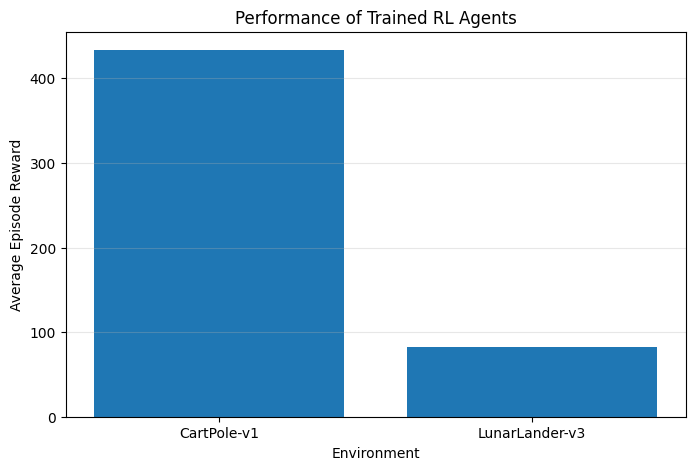


CartPole Average Reward: 433.40
LunarLander Average Reward: 82.51

Higher average reward indicates better performance within the respective environment.


In [3]:
!pip -q install "stable-baselines3[extra]" "gymnasium[box2d]"
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy
from IPython.display import display
print("TRAINING CARTPOLE AGENT...")
print("The agent learns to keep the pole balanced.")
cartpole_env = gym.make("CartPole-v1")
print("\nObservation Space:", cartpole_env.observation_space)
print("Action Space:", cartpole_env.action_space)
cartpole_model = PPO(
    "MlpPolicy",
    cartpole_env,
    verbose=0,
    seed=42)
cartpole_model.learn(
    total_timesteps=10000)
cartpole_mean_reward, cartpole_std_reward = evaluate_policy(
    cartpole_model,
    cartpole_env,
    n_eval_episodes=10,
    deterministic=True)
cartpole_env.close()
print("\nCartPole training completed.")
print("Average Reward:", round(cartpole_mean_reward, 2))
print("Reward Std.:", round(cartpole_std_reward, 2))
print("TRAINING LUNARLANDER AGENT")
print("The agent learns to land the spacecraft safely.")
lander_env = gym.make("LunarLander-v3")
print("\nObservation Space:", lander_env.observation_space)
print("Action Space:", lander_env.action_space)
lander_model = PPO(
    "MlpPolicy",
    lander_env,
    verbose=0,
    seed=42)
lander_model.learn(
    total_timesteps=200000)
lander_mean_reward, lander_std_reward = evaluate_policy(
    lander_model,
    lander_env,
    n_eval_episodes=10,
    deterministic=True)
lander_env.close()
print("\nLunarLander training completed.")
print("Average Reward:", round(lander_mean_reward, 2))
print("Reward Std.:", round(lander_std_reward, 2))
results = pd.DataFrame({
    "Environment": [
        "CartPole-v1",
        "LunarLander-v3"],
    "Algorithm": [
        "PPO",
        "PPO"],
    "Training Steps": [
        10000,
        200000],
    "Average Reward": [
        round(cartpole_mean_reward, 2),
        round(lander_mean_reward, 2)],
    "Reward Std.": [
        round(cartpole_std_reward, 2),
        round(lander_std_reward, 2)]})
print("REINFORCEMENT LEARNING RESULTS")
display(results)
plt.figure(figsize=(8, 5))
plt.bar(
    results["Environment"],
    results["Average Reward"])
plt.title("Performance of Trained RL Agents")
plt.xlabel("Environment")
plt.ylabel("Average Episode Reward")
plt.grid(
    axis="y",
    alpha=0.3)
plt.show()
print(f"\nCartPole Average Reward: "
    f"{cartpole_mean_reward:.2f}")
print(f"LunarLander Average Reward: "
    f"{lander_mean_reward:.2f}")
print("\nHigher average reward indicates better "
    "performance within the respective environment.")